# FESP (Formulario en Español)

## Objetivo

Simplificar la creación de formularios web utilizando instrucciones en español fáciles de recordar y transformar ese lenguaje en código HTML.

## Alcance

- Permitir la creación y finalización de formularios.
- Incorporar distintos tipos de campos.
- Permitir definir etiquetas y textos de ayuda (placeholder) para los campos.
- Permitir crear botones, incluyendo botones de envío.
- Permitir seleccionar el método HTTP del formulario (GET o POST).

La implementación utilizará Java y ANTLR4 para el análisis y procesamiento de las instrucciones, junto con Ollama para la generación de HTML. El resultado será un documento HTML que tendrá la estructura del formulario.

## Ejemplos

* **Un formulario vacío**

```
formulario "Registro", post
fin
```

genera:

```HTML

<!DOCTYPE html>
<html lang="es">
<head>
	<meta charset="UTF-8">
	<meta name="viewport" content="width=device-width, initial-scale=1.0">
	<title>Registro</title>
</head>
<body>
	<form method="post">
	</form>
</body>
</html>
```

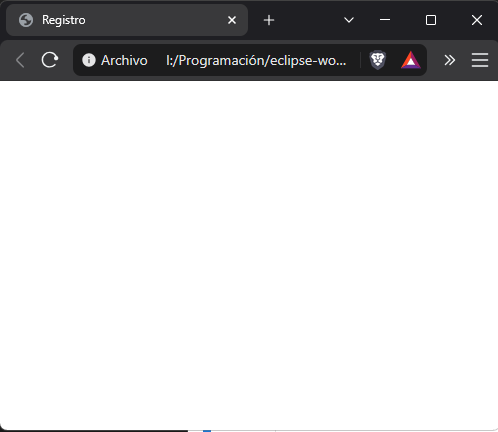


* **Un formulario completo**

```
 formulario "Contacto", post
    campo texto, etiqueta "Nombre", placeholder "Ingrese nombre"
    campo texto, placeholder "Ingrese apellido"
    campo numero, etiqueta "Telefono", placeholder "Ej. 1122334455"
    campo correo, etiqueta "Correo", placeholder "Ej. micorreo@ejemplo.com"
    campo contraseña, etiqueta "Clave"
    campo area, etiqueta "Descripcion"
    boton enviar "Registrar"
    boton "Cancelar"
 fin
```

genera:

```HTML
<!DOCTYPE html>
<html lang="es">
<head>
	<meta charset="UTF-8">
	<meta name="viewport" content="width=device-width, initial-scale=1.0">
	<title>Contacto</title>
</head>
<body>
	<form method="post">
		<label for="campo_1">Nombre</label>
		<input type="text" id="campo_1" name="campo_1" placeholder="Ingrese nombre">
		<input type="text" id="campo_2" name="campo_2" placeholder="Ingrese apellido">
		<label for="campo_3">Telefono</label>
		<input type="number" id="campo_3" name="campo_3" placeholder="Ej. 1122334455">
		<label for="campo_4">Correo</label>
		<input type="email" id="campo_4" name="campo_4" placeholder="Ej. micorreo@ejemplo.com">
		<label for="campo_5">Clave</label>
		<input type="password" id="campo_5" name="campo_5">
		<label for="campo_6">Descripcion</label>
		<textarea id="campo_6" name="campo_6"></textarea>
		<button type="submit">Enviar</button>
		<button type="button">Cancelar</button>
	</form>
</body>
</html>
```

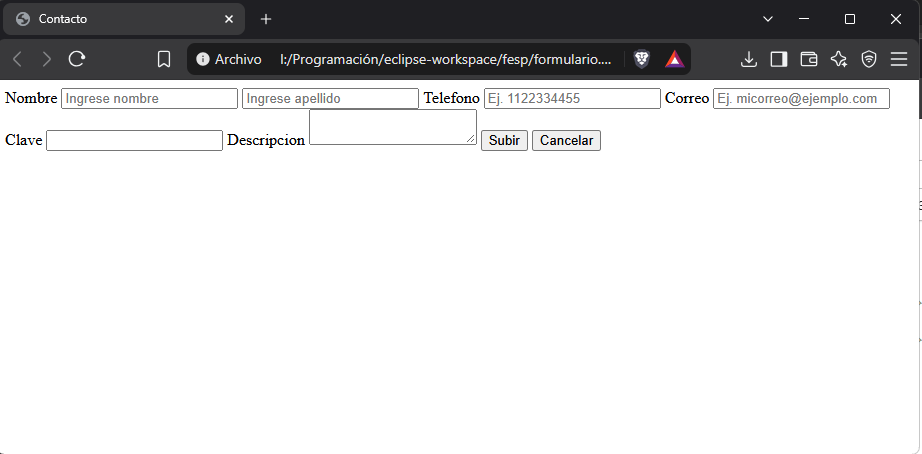

## Especificaciones léxicas

| Lexema | Token | Patrón |
|---|---|---|
| formulario | FORM | `'formulario'` |
| get | GET | `'get'` |
| post | POST | `'post'` |
| fin | FIN | `'fin'` |
| campo | CAMPO | `'campo'` |
| texto | TXT | `'texto'` |
| contraseña | PASS | `'contraseña'` |
| correo | CORREO | `'correo'` |
| numero | NUMERO | `'numero'` |
| area | AREA | `'area'` |
| etiqueta | ETIQ | `'etiqueta'` |
| placeholder | PH | `'placeholder'` |
| boton | BOTON | `'boton'` |
| enviar | ENVIAR | `'enviar'` |
| , | COMA | `','` |
| "nombre" | CAD | `'"' ~["\r\n]* '"'` |
| espacios y saltos | ESPA | `[ \t\r\n]+` |

## Especificaciones sintácticas

`<Formulario>` ::= FORM CAD COMA `<Metodo>` `<Cuerpo>` FIN

`<Metodo>` ::= GET | POST

`<Cuerpo>` ::= `<Elemento>` `<Cuerpo>` | λ

`<Elemento>` ::= `<Campo>` | `<Boton>`

`<Campo>` ::= CAMPO `<TipoCampo>` COMA `<Propiedades>`

`<TipoCampo>` ::= TXT
                 | PASS
                 | CORREO
                 | NUMERO
                 | AREA

`<Propiedades>` ::= `<Propiedad>`
                   | `<Propiedad>` COMA `<Propiedades>`

`<Propiedad>` ::= `<Etiqueta>` | `<Placeholder>`

`<Etiqueta>` ::= ETIQ CAD

`<Placeholder>` ::= PH CAD

`<Boton>` ::= BOTON `<TipoBoton>` CAD

`<TipoBoton>` ::= ENVIAR | λ

## Especificaciones semánticas

| **Regla** | **Acciones semánticas** |
|---|---|
| `<Formulario>` ::= FORM CAD COMA `<Metodo>` `<Cuerpo>` FIN | Crear una página con un formulario HTML. Recibir una cadena que será el título (`<title>`) y especificar el método con el cual trabajará el formulario. |
| `<Metodo>` ::= GET | Trad: `<form method="get">` |
| `<Metodo>` ::= POST | Trad: `<form method="post">` |
| `<Cuerpo>` ::= `<Elemento>` `<Cuerpo>` | Muchos elementos. |
| `<Cuerpo>` ::= λ | Ningún elemento. |
| `<Elemento>` ::= `<Campo>` | Procesar un campo de entrada y agregar el elemento HTML generado. |
| `<Elemento>` ::= `<Boton>` | Procesar un botón y agregar el elemento HTML generado. |
| `<Campo>` ::= CAMPO `<TipoCampo>` COMA `<Propiedades>` | Obtener el tipo de campo y sus propiedades. Generar un identificador único para el campo y comprobar que no existan propiedades repetidas del mismo tipo. |
| `<TipoCampo>` ::= TXT | Asignar el tipo HTML text al campo. Trad: `type="text"` |
| `<TipoCampo>` ::= PASS | Asignar el tipo HTML password al campo. Trad: `type="password"` |
| `<TipoCampo>` ::= CORREO | Asignar el tipo HTML email al campo. Trad: `type="email"` |
| `<TipoCampo>` ::= NUMERO | Asignar el tipo HTML number al campo. Trad: `type="number"` |
| `<TipoCampo>` ::= AREA | Generar un elemento HTML `<textarea>` para representar un campo de área de texto. |
| `<Propiedades>` ::= `<Propiedad>` | Procesar la propiedad especificada y asignar su valor al campo. |
| `<Propiedades>` ::= `<Propiedad>` COMA `<Propiedades>` | Procesar la propiedad actual y continuar procesando las propiedades restantes. |
| `<Propiedad>` ::= `<Etiqueta>` | Obtener el texto de la etiqueta y generar el elemento HTML `<label>`, asociado al campo mediante su identificador. Verificar que el campo no tenga otra etiqueta. |
| `<Propiedad>` ::= `<Placeholder>` | Obtener el texto del placeholder y utilizarlo como atributo del campo HTML. Verificar que el campo no tenga otro placeholder. |
| `<Etiqueta>` ::= ETIQ CAD | Trad: `<label for="ID_Generado"> CAD </label>` |
| `<Placeholder>` ::= PH CAD | Trad: `placeholder= CAD` |
| `<Boton>` ::= BOTON `<TipoBoton>` CAD | Obtener el texto del botón y determinar su comportamiento según el tipo de botón. |
| `<TipoBoton>` ::= ENVIAR | Trad: `<button type="submit"> CAD </button>` |
| `<TipoBoton>` ::= λ | Trad: `<button type="button"> CAD </button>` |

## Implementación

La implementación del lenguaje FESP se realizó utilizando Java y ANTLR4.

ANTLR4 se encarga del análisis léxico y sintáctico de las instrucciones escritas en FESP, generando un árbol de análisis que permite recorrer y procesar cada elemento del formulario.

A partir de ese árbol, Java obtiene la información del formulario y utiliza Ollama para generar los fragmentos de código HTML correspondientes a sus campos y botones.

Finalmente, se construye el documento HTML completo y se guarda en un archivo llamado `formulario.html`.

### FESP.g4

```antlr
grammar FESP;

// Reglas sintácticas

formulario
    : FORM CAD COMA metodo cuerpo FIN EOF
    ;

metodo
    : GET
    | POST
    ;

cuerpo
    : elemento*
    ;

elemento
    : campo
    | boton
    ;

campo
    : CAMPO tipo_campo COMA propiedades
    ;

tipo_campo
    : TXT
    | PASS
    | CORREO
    | NUMERO
    | AREA
    ;

propiedades
    : propiedad (COMA propiedad)*
    ;

propiedad
    : etiqueta
    | placeholder
    ;

etiqueta
    : ETIQ CAD
    ;

placeholder
    : PH CAD
    ;

boton
    : BOTON ENVIAR? CAD
    ;

// Reglas léxicas

FORM   : 'formulario';
FIN    : 'fin';
CAMPO  : 'campo';
GET    : 'get';
POST   : 'post';

TXT    : 'texto';
PASS   : 'contraseña';
CORREO : 'correo';
NUMERO : 'numero';
AREA   : 'area';

ETIQ   : 'etiqueta';
PH     : 'placeholder';

BOTON  : 'boton';
ENVIAR : 'enviar';

COMA   : ',';

CAD    : '"' ~["\r\n]* '"';

ESPA   : [ \t\r\n]+ -> skip;

### ManejadorErrores.java

```java
package com.fesp;

import org.antlr.v4.runtime.BaseErrorListener;
import org.antlr.v4.runtime.Recognizer;
import org.antlr.v4.runtime.RecognitionException;

public class ManejadorErrores extends BaseErrorListener {

    private boolean hayErrores = false;

    @Override
    public void syntaxError(Recognizer<?, ?> recognizer, Object simbolo,
                            int linea, int columna, String mensaje,
                            RecognitionException exception) {

        hayErrores = true;

        String tipoError;

        if (recognizer instanceof org.antlr.v4.runtime.Lexer) {
            tipoError = "Error Léxico";
        } else {
            tipoError = "Error sintáctico";
        }

        System.out.println(tipoError + " en línea " + linea
                + ", columna " + columna + ": " + mensaje);
    }

    public boolean hayErrores() {
        return hayErrores;
    }
}

### GeneradorOllama.java

```java
package com.fesp;

import java.net.URI;
import java.net.http.HttpClient;
import java.net.http.HttpRequest;
import java.net.http.HttpResponse;
import java.time.Duration;

import com.google.gson.Gson;
import com.google.gson.JsonArray;
import com.google.gson.JsonObject;
import com.google.gson.JsonParser;

public class GeneradorOllama {

    private static final HttpClient CLIENTE = HttpClient.newHttpClient();

    public String generarTagHtml(String tag, String texto, String atributo)
            throws Exception {

        // Construir el mensaje para Ollama
        String instruccion;

        if (!tag.equals("button") &&
                !tag.equals("text") &&
                !tag.equals("password") &&
                !tag.equals("email") &&
                !tag.equals("number") &&
                !tag.equals("textarea")) {

            throw new IllegalArgumentException(
                    "Tipo de elemento HTML no permitido: " + tag
            );
        }

        if (tag.equals("button")) {

            instruccion = """
                    Devuelve únicamente código HTML.
                    Genera un elemento HTML button.

                    Reglas obligatorias:
                    - Solamente agrega esto: atributo type= "%s" y luego de '>' %s. Nada más.
                    - No utilices input.
                    - Conserva exactamente el texto indicado.
                    - No agregues explicaciones ni markdown.<

                    """.formatted(atributo, texto);

        } else if (tag.equals("textarea")) {

            instruccion = """
                    Genera únicamente el elemento HTML textarea.
                    No uses markdown ni explicaciones.

                    El elemento debe cumplir estas reglas:
                    -obligatorio incluir atributo id y name con %s
                    %s
                    - No agregues otros atributos.
                    - Devuelve solamente el elemento HTML.
                    - No utilices table, div, p, ni ningún otro elemento contenedor.
                    - No agregues ningún elemento HTML adicional.
                    - Es obligatorio comenzar con <textarea> y obligatorio escribir </textarea> antes de terminar.
                    """.formatted(
                    texto.toLowerCase().replace(" ", "_"),
                    atributo != null
                            ? "- Agrega el atributo placeholder con el texto: \"" + atributo + "\".\n"
                            : ""
            );

        } else {

            String atributoPlaceholder = "";

            if (atributo != null) {
                atributoPlaceholder = "- Agrega el atributo placeholder con el texto: \""
                        + atributo + "\".\n";
            }

            instruccion = """
                    Genera únicamente un elemento HTML input.
                    No uses markdown ni explicaciones.
                    El elemento debe cumplir estas reglas:
                    - type debe ser "%s".
                    %s
                    - No agregues otros atributos.
                    Devuelve solamente el elemento HTML.
                    """.formatted(tag, atributoPlaceholder);
        }

        // Construir la solicitud JSON
        JsonObject mensaje = new JsonObject();
        mensaje.addProperty("role", "user");
        mensaje.addProperty("content", instruccion);

        JsonArray mensajes = new JsonArray();
        mensajes.add(mensaje);

        JsonObject solicitudJson = new JsonObject();
        solicitudJson.addProperty("model", "llama3.2:1b");
        solicitudJson.add("messages", mensajes);
        solicitudJson.addProperty("stream", false);

        // Convertir el JSON a String
        String json = new Gson().toJson(solicitudJson);

        // Enviar solicitud HTTP
        HttpRequest solicitud = HttpRequest.newBuilder()
                .uri(URI.create("http://localhost:11434/api/chat"))
                .header("Content-Type", "application/json")
                .timeout(Duration.ofMinutes(3))
                .POST(HttpRequest.BodyPublishers.ofString(json))
                .build();

        HttpResponse<String> respuesta = CLIENTE.send(
                solicitud,
                HttpResponse.BodyHandlers.ofString()
        );

        if (respuesta.statusCode() != 200) {
            throw new RuntimeException(
                    "Error al comunicarse con Ollama: "
                            + respuesta.statusCode()
            );
        }

        // Extraer el contenido generado
        JsonObject jsonRespuesta = JsonParser
                .parseString(respuesta.body())
                .getAsJsonObject();

        String html = jsonRespuesta
                .getAsJsonObject("message")
                .get("content")
                .getAsString();

        // Eliminar posibles bloques Markdown
        html = html.replace("```html", "")
                .replace("```", "")
                .trim();

        System.out.println("HTML recibido de Ollama:");
        System.out.println("[" + html + "]");

        // Validar el elemento generado
        if (tag.equals("button")) {
            html = validarBoton(html, texto, atributo);
        } else {
            html = validarCampo(html, tag, texto, atributo);
        }

        return html;
    }

    private String validarBoton(String html, String texto, String atributo) {

        if (!html.contains("type=\"" + atributo + "\"")) {
            html = html.replaceFirst(
                    "<button>",
                    "<button type= \"" + atributo + "\">"
            );

            System.out.println("HTML corregido por Java:");
            System.out.println("[" + html + "]");
        }

        if (!html.matches(
                "(?s)<button type=\"" + atributo + "\">.*</button>"
        )) {
            throw new RuntimeException(
                    "Ollama generó un botón HTML no válido."
            );
        }

        return html;
    }

    private String validarCampo(String html, String tag,
            String id, String placeholder) {

        if (tag.equals("textarea")) {

            if (!html.contains("</textarea>")) {
                html += "</textarea>";
            }

            if (!html.matches("(?s)\\s*<textarea\\b[^>]*>.*</textarea>\\s*")) {
                throw new RuntimeException(
                        "Ollama generó un área de texto HTML no válida."
                );
            }

            String atributoPlaceholder = placeholder != null
                    ? " placeholder=\"" + escaparHtml(placeholder) + "\""
                    : "";

            return "<textarea id=\"" + escaparHtml(id)
                    + "\" name=\"" + escaparHtml(id) + "\""
                    + atributoPlaceholder + "></textarea>";

        } else {

            if (!html.matches("(?s)\\s*<input\\b[^>]*?/?>\\s*")) {
                throw new RuntimeException(
                        "Ollama generó un campo HTML no válido."
                );
            }

            String atributoPlaceholder = placeholder != null
                    ? " placeholder=\"" + escaparHtml(placeholder) + "\""
                    : "";

            return "<input type=\"" + tag
                    + "\" id=\"" + escaparHtml(id)
                    + "\" name=\"" + escaparHtml(id) + "\""
                    + atributoPlaceholder + ">";
        }
    }

    private String escaparHtml(String texto) {
        return texto.replace("&", "&amp;")
                .replace("<", "&lt;")
                .replace(">", "&gt;")
                .replace("\"", "&quot;")
                .replace("'", "&#39;");
    }
}

### GeneradorHtml.java

```java
package com.fesp;

public class GeneradorHtml extends FESPBaseListener {

    private StringBuilder elementos = new StringBuilder();
    private String tituloFormulario;
    private String metodoFormulario;
    private GeneradorOllama generadorOllama = new GeneradorOllama();
    private int contadorCampos = 0;

    // Campo de texto
    @Override
    public void exitCampo(FESPParser.CampoContext ctx) {

        String tipo = ctx.tipo_campo().getText();

        String etiqueta = null;
        String placeholder = null;

        // Buscamos si el campo tiene una etiqueta
        for (FESPParser.PropiedadContext propiedad :
                ctx.propiedades().propiedad()) {

            if (propiedad.etiqueta() != null) {

                if (etiqueta != null) {
                    throw new RuntimeException(
                            "Un campo no puede tener más de una etiqueta."
                    );
                }

                etiqueta = propiedad.etiqueta().CAD().getText();
                etiqueta = etiqueta.substring(1, etiqueta.length() - 1);
            }

            if (propiedad.placeholder() != null) {

                if (placeholder != null) {
                    throw new RuntimeException(
                            "Un campo no puede tener más de un placeholder."
                    );
                }

                placeholder = propiedad.placeholder().CAD().getText();
                placeholder = placeholder.substring(1, placeholder.length() - 1);
            }
        }

        if (etiqueta == null && placeholder == null) {
            throw new RuntimeException(
                    "El campo necesita una etiqueta o un placeholder."
            );
        }

        String id = generarID();

        // Genera la etiqueta HTML
        if (etiqueta != null) {

            String etiquetaHtml = escaparHtml(etiqueta);

            elementos.append("\t\t<label for=\"").append(id).append("\">")
                    .append(etiquetaHtml).append("</label>\n");
        }

        // Convertimos el tipo de campo de FESP al tipo HTML
        String tipoHtml;

        switch (tipo) {
            case "texto":
                tipoHtml = "text";
                break;

            case "contraseña":
                tipoHtml = "password";
                break;

            case "correo":
                tipoHtml = "email";
                break;

            case "numero":
                tipoHtml = "number";
                break;

            case "area":
                tipoHtml = "textarea";
                break;

            default:
                throw new RuntimeException("Tipo de campo no implementado: " + tipo);
        }

        // Ollama genera el input
        try {
            String htmlInput = generadorOllama.generarTagHtml(
                    tipoHtml,
                    id,
                    placeholder
            );

            elementos.append("\t\t").append(htmlInput).append("\n");

        } catch (Exception e) {
            e.printStackTrace();
            throw new RuntimeException("No se pudo generar el campo con Ollama.", e);
        }
    }

    // Botón enviar
    @Override
    public void exitBoton(FESPParser.BotonContext ctx) {

        String texto = ctx.CAD().getText();

        texto = texto.substring(1, texto.length() - 1);
        texto = escaparHtml(texto);

        String tipoBoton = ctx.ENVIAR() != null ? "submit" : "button";

        try {

            String htmlBoton = generadorOllama.generarTagHtml(
                    "button",
                    texto,
                    tipoBoton
            );

            elementos.append("\t\t").append(htmlBoton).append("\n");

        } catch (Exception e) {

            throw new RuntimeException(
                    "No se pudo generar el botón con Ollama.", e
            );
        }
    }

    // Obtener el HTML
    public String obtenerHtml() {
        return "<!DOCTYPE html>\n"
                + "<html lang=\"es\">\n"
                + "<head>\n"
                + "\t<meta charset=\"UTF-8\">\n"
                + "\t<meta name=\"viewport\" content=\"width=device-width, initial-scale=1.0\">\n"
                + "\t<title>" + tituloFormulario + "</title>\n"
                + "</head>\n"
                + "<body>\n"
                + "\t<form method=\"" + metodoFormulario + "\">\n"
                + elementos
                + "\t</form>\n"
                + "</body>\n"
                + "</html>";
    }

    @Override
    public void exitFormulario(FESPParser.FormularioContext ctx) {

        tituloFormulario = ctx.CAD().getText();
        tituloFormulario = tituloFormulario.substring(1, tituloFormulario.length() - 1);
        tituloFormulario = escaparHtml(tituloFormulario);

        metodoFormulario = ctx.metodo().getText();
    }

    private String generarID() {
        contadorCampos++;
        return "campo_" + contadorCampos;
    }

    private String escaparHtml(String texto) {
        return texto.replace("&", "&amp;")
                .replace("<", "&lt;")
                .replace(">", "&gt;")
                .replace("\"", "&quot;")
                .replace("'", "&#39;");
    }
}
```

### Main.java

```java
package com.fesp;

import com.fesp.FESPLexer;
import com.fesp.FESPParser;

import org.antlr.v4.runtime.*;
import org.antlr.v4.runtime.tree.ParseTreeWalker;

import java.io.IOException;
import java.nio.charset.StandardCharsets;
import java.nio.file.Files;
import java.nio.file.Path;

public class Main {

    public static void main(String[] args) throws IOException {

        String codigo = """
                formulario "Contacto", post
                campo texto, etiqueta "Nombre", placeholder "Ingrese nombre"
                campo texto, placeholder "Ingrese apellido"
                campo numero, etiqueta "Telefono", placeholder "Ej. 1122334455"
                campo correo, etiqueta "Correo", placeholder "Ej. micorreo@ejemplo.com"
                campo contraseña, etiqueta "Clave"
                campo area, etiqueta "Descripcion"
                boton enviar "Registrar"
                boton "Cancelar"
                fin
                """;

        // Reconocer los caracteres y formar los tokens
        FESPLexer lexer = new FESPLexer(CharStreams.fromString(codigo));

        // Pasar los tokens al parser
        CommonTokenStream tokens = new CommonTokenStream(lexer);
        FESPParser parser = new FESPParser(tokens);

        ManejadorErrores manejador = new ManejadorErrores();

        lexer.removeErrorListeners();
        lexer.addErrorListener(manejador);

        parser.removeErrorListeners();
        parser.addErrorListener(manejador);

        // Analizar el programa según la regla inicial
        FESPParser.FormularioContext arbol = parser.formulario();

        if (manejador.hayErrores()) {
            System.out.println("No se pudo generar el HTML debido a errores en el "
                    + "código FESP.");
            return;
        }

        GeneradorHtml generador = new GeneradorHtml();
        ParseTreeWalker.DEFAULT.walk(generador, arbol);

        String html = generador.obtenerHtml();

        Path archivo = Path.of("formulario.html");

        Files.writeString(
                archivo,
                html,
                StandardCharsets.UTF_8
        );

        System.out.println("HTML generado en: " + archivo.toAbsolutePath());
    }
}
```

### ProcesadorFESP.java

```java
package com.fesp;

import org.antlr.v4.runtime.*;
import org.antlr.v4.runtime.tree.ParseTreeWalker;

public class ProcesadorFESP {

    public String procesar(String codigo) {

        FESPLexer lexer = new FESPLexer(CharStreams.fromString(codigo));

        CommonTokenStream tokens = new CommonTokenStream(lexer);

        FESPParser parser = new FESPParser(tokens);

        ManejadorErrores manejador = new ManejadorErrores();

        lexer.removeErrorListeners();
        lexer.addErrorListener(manejador);

        parser.removeErrorListeners();
        parser.addErrorListener(manejador);

        FESPParser.FormularioContext arbol = parser.formulario();

        if (manejador.hayErrores()) {
            throw new RuntimeException("El código FESP contiene errores.");
        }

        GeneradorHtml generador = new GeneradorHtml();

        ParseTreeWalker.DEFAULT.walk(generador, arbol);

        return generador.obtenerHtml();
    }
}
```

## Conclusiones

A través del desarrollo de FESP se logró implementar un lenguaje de propósito específico que permite maquetar formularios web mediante instrucciones sencillas en español y transformarlas en código HTML.

Se trabajó con ANTLR4 para definir la estructura léxica y sintáctica del lenguaje, utilizando Java para implementar el procesamiento de las instrucciones, validar el código y realizar la traducción a HTML.

Se incorporó Ollama como herramienta de generación de código HTML. Si bien su funcionamiento no es perfecto y fue necesario realizar algunos ajustes para obtener los resultados deseados, resultó de gran utilidad, especialmente para ahorrar tiempo durante la implementación.

Por otra parte, la incorporación de reglas semánticas permitió detectar situaciones que no representan errores sintácticos, como la repetición de etiquetas o placeholders dentro de un mismo campo. El funcionamiento del lenguaje fue comprobado mediante pruebas automatizadas.

Lo interesante de este proyecto es que cuenta con una estructura que permite seguir mejorándolo y ampliándolo a futuro.

En conclusión, se cumplió el objetivo propuesto: desarrollar una herramienta que simplifique la creación de formularios HTML mediante un lenguaje de instrucciones en español, haciendo uso de un metacompilador para el análisis del lenguaje y de la inteligencia artificial para realizar la traducción.